<a href="https://colab.research.google.com/github/lilajabali/beginning-bioinformatics/blob/main/notebooks/Copy_of_Supervised_Learning_Loss_and_Gradient_Descent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# How does a model learn?
## Loss, linear regression, gradient descent, and generalization

Use simulated gene-expression data to predict a quantitative cellular response.

By the end, you should be able to:
- Distinguish features, labels, predictions, residuals, and loss.
- Explain why direct least squares and gradient descent can fit the same model.
- Diagnose learning rates that are too small or too large.
- Explain why low training loss does not guarantee good predictions.
- Identify a preprocessing step that leaks information from held-out samples.

**Workflow:** predict what will happen → run the cell → interpret the result.

### Record your answers in the response cells.

## 1. Features and labels: what makes learning supervised?
Common data structure:
* Each **row** is a biological sample.
* One or more of the **columns** are "features" **X** variables that are measured in the experiment.
* One column contains the "labels" **y**

**Supervised learning uses known responses to estimate a rule for predicting new responses.**

In the example below, one gene's standardized log-expression is the feature, and a continuous cellular response is the label.

Standardization means the feature is expressed relative to a reference mean and standard deviation. Negative values indicate below-average expression; they do not mean negative transcript counts.

,sample,gene_expression_z,response
0,S01,-2.000000,4.080714
1,S02,-1.897436,2.106389
2,S03,-1.794872,5.537154
3,S04,-1.692308,5.975679
4,S05,-1.589744,4.092972


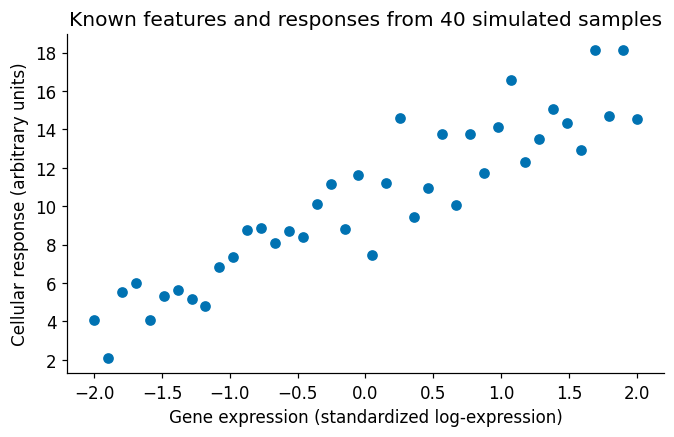

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.feature_selection import SelectKBest, f_regression

try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass  # Also works in a local Jupyter environment.

plt.rcParams.update({'figure.dpi': 110, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
BLUE, ORANGE, GREEN = '#0072B2', '#D55E00', '#009E73'
rng = np.random.default_rng(5340)
x = np.linspace(-2, 2, 40)
y = 10 + 3*x + rng.normal(0, 1.6, len(x))
samples = pd.DataFrame({'sample': [f'S{i+1:02d}' for i in range(len(x))],
                        'gene_expression_z': x, 'response': y})
display(samples.head())
plt.figure(figsize=(7, 4))
plt.scatter(x, y, color=BLUE)
plt.xlabel('Gene expression (standardized log-expression)')
plt.ylabel('Cellular response (arbitrary units)')
plt.title('Known features and responses from 40 simulated samples')
plt.show()

**Predict and discuss:** What is a feature? What is the label? If an unknown sample
has expression = 1, roughly what response would you predict? Could this plot
alone demonstrate that the gene causes the response?

**Your response:** gene expression, cellular response, 14, no because the plot only shows association but not causation

## 2. From a prediction to a loss function
Our model is a straight line:
$$
\hat y_i = b + w x_i.
$$
The intercept **b** is the predicted response at x = 0. The slope **w** is the
change in predicted response per unit of expression. These are model parameters.

A **residual** is observed minus predicted response: $e_i=y_i-\hat y_i$.

Mean squared error summarizes the errors in one number:
$$
L(b,w)=\frac{1}{n}\sum_{i=1}^n(y_i-b-wx_i)^2.
$$
Squaring prevents positive and negative residuals from canceling and gives
larger errors more weight. MSE has squared response units; RMSE = √MSE has
the original response units. There is no universal threshold for a 'good' MSE.

**A small worked example:** for x = [2, 4, 6, 8], observed responses
[5, 7, 10, 13], and the candidate line ŷ = 1.5x, predictions are
[3, 6, 9, 12]. Residuals are [2, 1, 1, 1], so
MSE = (4 + 1 + 1 + 1)/4 = **1.75**. This is one candidate line, not necessarily
the best-fitting line. The plots below use our separate 40-sample dataset.

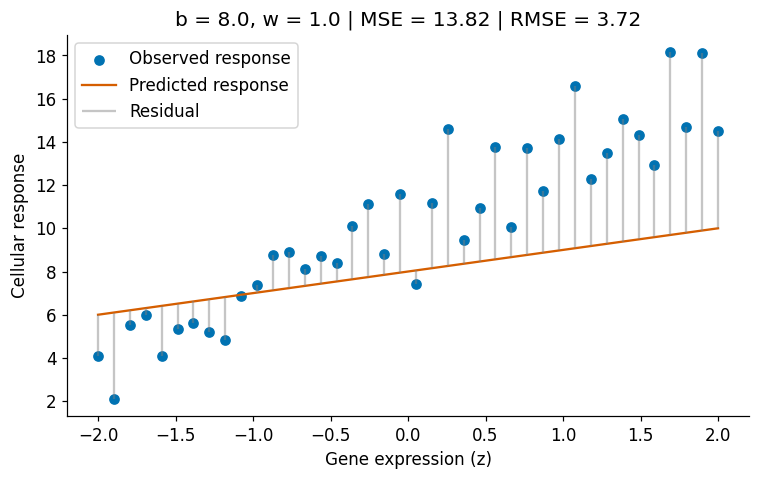

,x,observed,predicted,residual,squared_error
0,-2.000,4.081,6.000,-1.919,3.684
1,-1.897,2.106,6.103,-3.996,15.969
2,-1.795,5.537,6.205,-0.668,0.446
3,-1.692,5.976,6.308,-0.332,0.110
4,-1.590,4.093,6.410,-2.317,5.370
5,-1.487,5.325,6.513,-1.188,1.410


Mean residual = 2.214; MSE uses all 40 samples.


In [ ]:
def inspect_line(b=8.0, w=1.0):
    prediction = b + w*x
    residual = y - prediction
    loss = np.mean(residual**2)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.scatter(x, y, c=BLUE, label='Observed response')
    ax.plot(x, prediction, c=ORANGE, label='Predicted response')
    ax.vlines(x, prediction, y, color='gray', alpha=.45, label='Residual')
    ax.set(xlabel='Gene expression (z)', ylabel='Cellular response',
           title=f'b = {b:.1f}, w = {w:.1f} | MSE = {loss:.2f} | RMSE = {np.sqrt(loss):.2f}')
    ax.legend(loc='upper left')
    plt.show()
    display(pd.DataFrame({'x': x, 'observed': y, 'predicted': prediction,
                          'residual': residual, 'squared_error': residual**2}).head(6).round(3))
    print(f'Mean residual = {residual.mean():.3f}; MSE uses all {len(x)} samples.')

inspect_line(b=8, w=1)  # Fallback: edit these values and rerun.

In [ ]:
import ipywidgets as widgets
line_control = widgets.interactive(
    inspect_line,
    b=widgets.FloatSlider(value=8, min=4, max=16, step=.2, description='Intercept b', continuous_update=False),
    w=widgets.FloatSlider(value=1, min=-2, max=7, step=.1, description='Slope w', continuous_update=False))
display(line_control)

interactive(children=(FloatSlider(value=8.0, continuous_update=False, description='Intercept b', max=16.0, min…

**Try it:** Find a low-loss line by adjusting both sliders. Then increase the
intercept by 3 while holding the slope fixed. Describe which residuals change.
Why can mean residual be nearly zero even when predictions are poor?

**Your response:** 10.20, 3.20, 2.33 Because the positive and negative residuals cancel out and sum up close to zero

## 3. Fit the same model directly
Least squares finds the parameters that minimize squared residuals. In matrix
notation, X contains an intercept column of ones and an expression column:
$$
\hat{\boldsymbol\beta}=(X^T X)^{-1}X^T y,\qquad \boldsymbol\beta=(b,w)^T.
$$
This formula assumes X has full column rank. We use `np.linalg.lstsq`, which
solves the least-squares problem numerically without explicitly inverting
$X^TX$, and also handles rank-deficient designs.

The **model** defines predictions. The **loss** defines error. The **optimizer**
finds parameters. They are separate choices.

Least squares: b = 10.2137, w = 3.1685, MSE = 2.3313
Simulation parameters: b = 10, w = 3. Noise causes fitted values to differ.


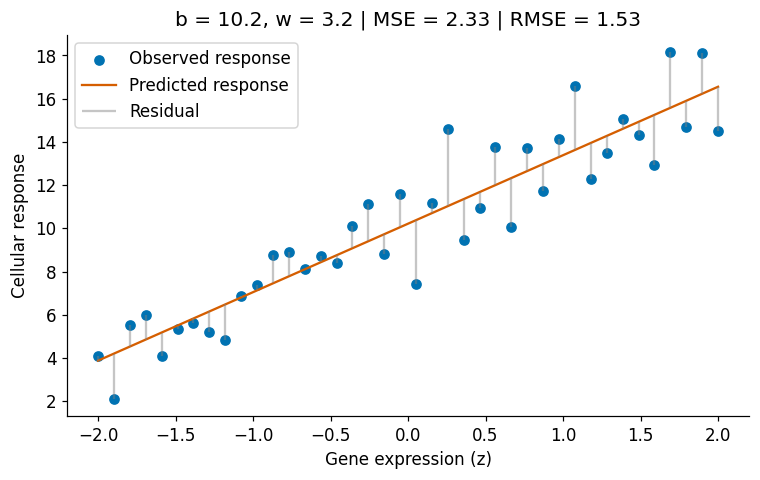

,x,observed,predicted,residual,squared_error
0,-2.000,4.081,3.877,0.204,0.042
1,-1.897,2.106,4.202,-2.095,4.390
2,-1.795,5.537,4.527,1.011,1.021
3,-1.692,5.976,4.852,1.124,1.264
4,-1.590,4.093,5.176,-1.084,1.174
5,-1.487,5.325,5.501,-0.176,0.031


Mean residual = 0.000; MSE uses all 40 samples.


In [ ]:
X = np.column_stack([np.ones(len(x)), x])
beta_direct, _, rank, _ = np.linalg.lstsq(X, y, rcond=None)
b_direct, w_direct = beta_direct
direct_mse = np.mean((y - X @ beta_direct)**2)
print(f'Least squares: b = {b_direct:.4f}, w = {w_direct:.4f}, MSE = {direct_mse:.4f}')
print('Simulation parameters: b = 10, w = 3. Noise causes fitted values to differ.')
inspect_line(b_direct, w_direct)

**Your response:** How does the direct solution compare with your slider fit? the direct solution is very close to the slider fit solution.
Why should the fitted slope differ from the slope used to generate the data?

## 4. Fit the same model iteratively: gradient descent
Start with a guess, calculate loss, and adjust the parameters. The gradient
points uphill; subtracting it moves downhill locally:
$$
\frac{\partial L}{\partial b}=-\frac{2}{n}\sum_i(y_i-b-wx_i),\qquad
\frac{\partial L}{\partial w}=-\frac{2}{n}\sum_i x_i(y_i-b-wx_i).
$$
$$
b_{t+1}=b_t-\alpha\frac{\partial L}{\partial b},\qquad
w_{t+1}=w_t-\alpha\frac{\partial L}{\partial w}.
$$
**α is the learning rate**, and t counts updates. Both gradients are computed
from the same current parameters before updating. This is full-batch gradient
descent: every update uses all samples.

**Predict:** How should the loss change with a small, moderate, or very large α?

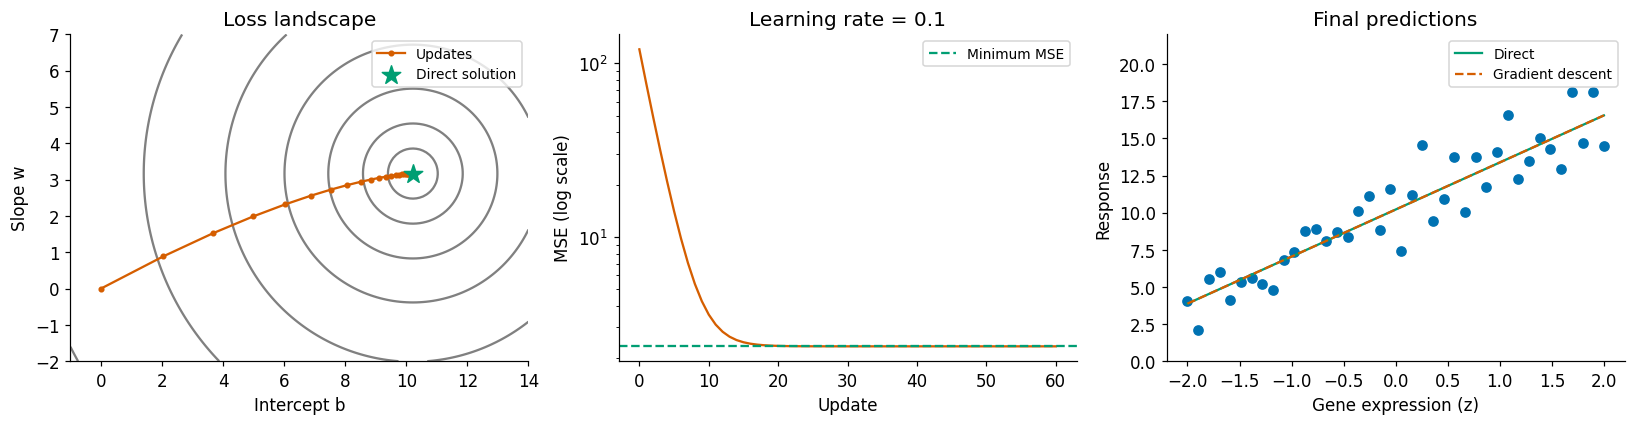

60 updates; final b, w = [10.21364965  3.16854025]; final MSE = 2.331


In [ ]:
def gradient_descent(X, y, learning_rate=.1, steps=100, initial=None):
    beta = np.zeros(X.shape[1]) if initial is None else np.array(initial, dtype=float)
    path, losses = [beta.copy()], [np.mean((y-X@beta)**2)]
    for _ in range(steps):
        gradient = (2 / len(y)) * X.T @ (X @ beta - y)
        beta = beta - learning_rate * gradient
        loss = np.mean((y-X@beta)**2)
        if not np.isfinite(loss):
            break
        path.append(beta.copy())
        losses.append(loss)
        if loss > 1e12:
            break  # Stop an unstable run before numeric overflow.
    return np.array(path), np.array(losses)

def show_descent(learning_rate=.1, steps=60):
    path, losses = gradient_descent(X, y, learning_rate, steps)
    b_grid, w_grid = np.meshgrid(np.linspace(-1, 14, 140), np.linspace(-2, 7, 120))
    surface = np.mean((y[:, None, None] - b_grid - x[:, None, None]*w_grid)**2, axis=0)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].contour(b_grid, w_grid, surface, levels=[3, 5, 10, 20, 40, 80, 160], colors='gray')
    axes[0].plot(path[:, 0], path[:, 1], 'o-', c=ORANGE, ms=3, label='Updates')
    axes[0].scatter(*beta_direct, marker='*', s=160, c=GREEN, label='Direct solution', zorder=5)
    axes[0].set(xlabel='Intercept b', ylabel='Slope w', xlim=(-1, 14), ylim=(-2, 7), title='Loss landscape')
    axes[0].legend(fontsize=9)
    axes[1].semilogy(losses, color=ORANGE)
    axes[1].axhline(direct_mse, color=GREEN, ls='--', label='Minimum MSE')
    axes[1].set(xlabel='Update', ylabel='MSE (log scale)', title=f'Learning rate = {learning_rate}')
    axes[1].legend(fontsize=9)
    axes[2].scatter(x, y, c=BLUE)
    axes[2].plot(x, X@beta_direct, color=GREEN, label='Direct')
    axes[2].plot(x, X@path[-1], color=ORANGE, ls='--', label='Gradient descent')
    axes[2].set(xlabel='Gene expression (z)', ylabel='Response', ylim=(0, 22), title='Final predictions')
    axes[2].legend(fontsize=9)
    plt.tight_layout()
    plt.show()
    print(f'{len(losses)-1} updates; final b, w = {path[-1]}; final MSE = {losses[-1]:.4g}')
    if losses[-1] > losses[0]:
        print('Loss increased: the learning rate is too large. Updates may leave the displayed plot range.')

show_descent(.1, 60)  # Fallback: try .005, .1, and .8.

In [ ]:
descent_control = widgets.interactive(
    show_descent,
    learning_rate=widgets.Dropdown(options=[('Slow: 0.005', .005), ('Moderate: 0.1', .1),
                                            ('Unstable: 0.8', .8)], value=.1, description='Rate'),
    steps=widgets.IntSlider(value=60, min=10, max=200, step=10, description='Updates', continuous_update=False))
display(descent_control)

interactive(children=(Dropdown(description='Rate', index=1, options=(('Slow: 0.005', 0.005), ('Moderate: 0.1',…

In [ ]:
path, losses = gradient_descent(X, y, learning_rate=.1, steps=200)
display(pd.DataFrame({'parameter': ['intercept b', 'slope w'],
                      'direct': beta_direct, 'gradient_descent': path[-1],
                      'absolute_difference': np.abs(beta_direct-path[-1])}))
print('Same coefficients within tolerance:', np.allclose(beta_direct, path[-1], atol=1e-6))
assert np.allclose(beta_direct, path[-1], atol=1e-6)

,parameter,direct,gradient_descent,absolute_difference
0,intercept b,10.213665,10.213665,1.776357e-15
1,slope w,3.168540,3.168540,4.440892e-16


Same coefficients within tolerance: True


**Your response:** Explain the three learning-rate outcomes. Is gradient descent
a different model? yes same model. If the parameters disagree, what should you check first?

**Scale matters:** the stable learning rate depends on the feature scales and
whether the loss uses a sum or mean. Standardizing predictors often improves
optimization. The numbers in this demonstration are not universal settings.

## 5. Training loss versus prediction on unseen samples
Our first fit used every sample to teach optimization. Its MSE measures fit to
those samples; it is not an independent estimate of predictive performance.

Now split a fresh simulated dataset **before fitting**:
- **Training:** estimate parameters.
- **Validation:** compare model choices such as polynomial degree.
- **Test:** evaluate the selected model once at the end.

The response below has modest curvature. Polynomial regression lets us change
model "flexibility" (i.e. curvature) while retaining least-squares fitting. Degree 1 is a line;
higher degrees add powers of x.

Overfitting arises when flexibility fits sample-specific noise as well as signal.
Note: running more gradient-descent updates is not the cause of overfitting.

Train: 60 | Validation: 30 | Test: 30


,degree,training_MSE,validation_MSE
0,1,7.784,6.848
1,2,4.071,4.809
2,3,4.056,4.989
3,5,3.852,4.965
4,8,3.582,5.512
5,12,3.427,5.309
6,25,2.198,425.184


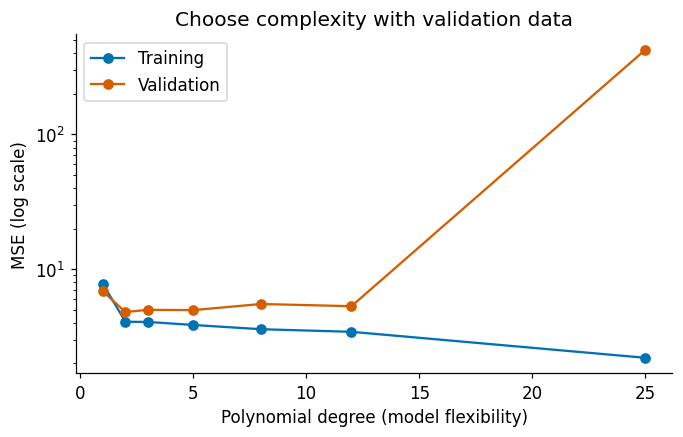

In [ ]:
rng_curve = np.random.default_rng(18)
x_curve = rng_curve.uniform(-2, 2, 120)
y_curve = 10 + 2*x_curve + 1.2*x_curve**2 + rng_curve.normal(0, 2, len(x_curve))
idx_trainval, idx_test = train_test_split(np.arange(120), test_size=.25, random_state=12)
idx_train, idx_val = train_test_split(idx_trainval, test_size=1/3, random_state=12)
xc_train, xc_val, xc_test = [x_curve[idx, None] for idx in [idx_train, idx_val, idx_test]]
yc_train, yc_val, yc_test = [y_curve[idx] for idx in [idx_train, idx_val, idx_test]]
print(f'Train: {len(yc_train)} | Validation: {len(yc_val)} | Test: {len(yc_test)}')

degrees = [1, 2, 3, 5, 8, 12, 25]
models, records = {}, []
for degree in degrees:
    model = make_pipeline(PolynomialFeatures(degree, include_bias=False),
                          StandardScaler(), LinearRegression())
    model.fit(xc_train, yc_train)
    models[degree] = model
    records.append({'degree': degree,
                    'training_MSE': mean_squared_error(yc_train, model.predict(xc_train)),
                    'validation_MSE': mean_squared_error(yc_val, model.predict(xc_val))})
scores = pd.DataFrame(records)
display(scores.round(3))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(scores.degree, scores.training_MSE, 'o-', color=BLUE, label='Training')
ax.plot(scores.degree, scores.validation_MSE, 'o-', color=ORANGE, label='Validation')
ax.set(xlabel='Polynomial degree (model flexibility)', ylabel='MSE (log scale)', yscale='log',
       title='Choose complexity with validation data')
ax.legend()
plt.show()

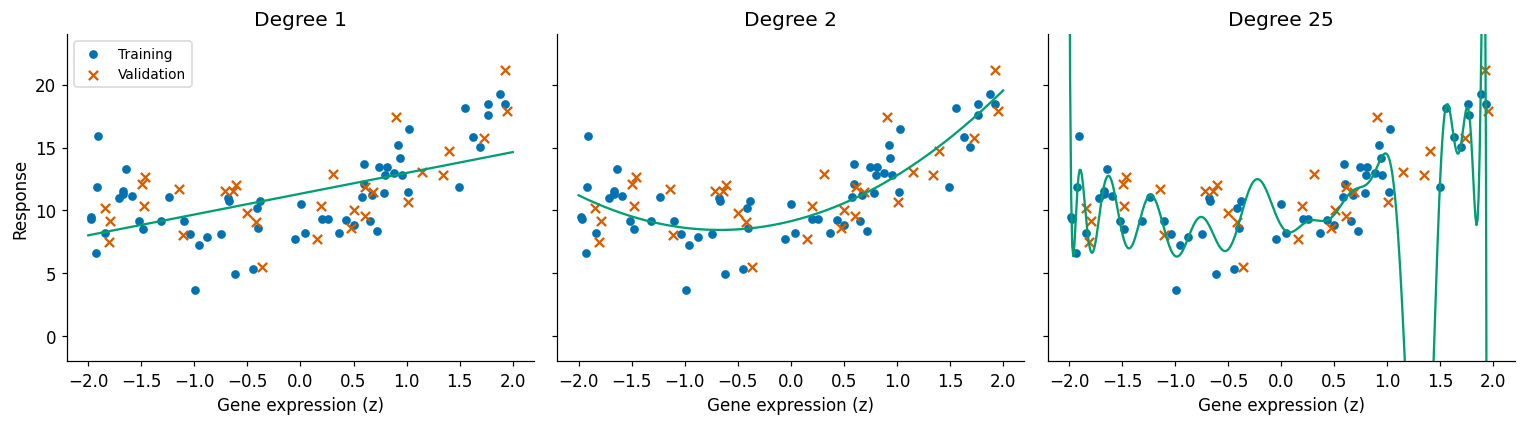

Fixed y limits make fits comparable; extreme high-degree predictions may extend beyond the panels.


In [ ]:
grid = np.linspace(-2, 2, 400)[:, None]
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, degree in zip(axes, [1, 2, 25]):
    ax.scatter(xc_train[:, 0], yc_train, color=BLUE, label='Training', s=22)
    ax.scatter(xc_val[:, 0], yc_val, color=ORANGE, label='Validation', marker='x')
    ax.plot(grid[:, 0], models[degree].predict(grid), color=GREEN)
    ax.set(title=f'Degree {degree}', xlabel='Gene expression (z)', ylim=(-2, 24))
axes[0].set_ylabel('Response')
axes[0].legend(fontsize=9)
plt.tight_layout()
plt.show()
print('Fixed y limits make fits comparable; extreme high-degree predictions may extend beyond the panels.')

**Pause before running the next cell.** Select a degree using validation MSE.
Which degree has the lowest training error? Is that the degree you would select?

**Your response:** degree 25. No because it will have more validation

Selected degree = 2
Final test MSE = 3.990; test RMSE = 1.997
Test R² = 0.697
Training-mean baseline test MSE = 13.982


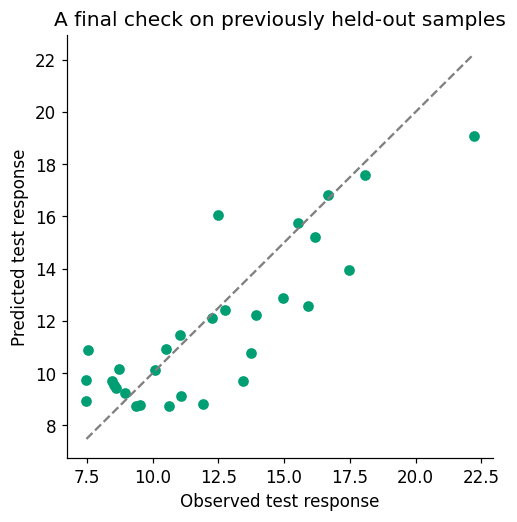

In [14]:
chosen_degree = int(scores.loc[scores.validation_MSE.idxmin(), 'degree'])
final_model = make_pipeline(PolynomialFeatures(chosen_degree, include_bias=False),
                            StandardScaler(), LinearRegression())
# After selecting complexity, refit using both training and validation samples.
final_model.fit(x_curve[idx_trainval, None], y_curve[idx_trainval])
test_prediction = final_model.predict(xc_test)
test_mse = mean_squared_error(yc_test, test_prediction)
baseline_prediction = np.full(len(yc_test), y_curve[idx_trainval].mean())
print(f'Selected degree = {chosen_degree}')
print(f'Final test MSE = {test_mse:.3f}; test RMSE = {np.sqrt(test_mse):.3f}')
print(f'Test R² = {r2_score(yc_test, test_prediction):.3f}')
print(f'Training-mean baseline test MSE = {mean_squared_error(yc_test, baseline_prediction):.3f}')
plt.figure(figsize=(5, 5))
plt.scatter(yc_test, test_prediction, color=GREEN)
limits = [min(yc_test.min(), test_prediction.min()), max(yc_test.max(), test_prediction.max())]
plt.plot(limits, limits, '--', color='gray')
plt.xlabel('Observed test response')
plt.ylabel('Predicted test response')
plt.title('A final check on previously held-out samples')
plt.show()

R² compares squared errors to a baseline that predicts the mean of the evaluated
responses; it can be negative. The separate baseline above uses a mean learned
from training + validation samples, which is available for deployment.

**Your response:** Does the selected model beat the baseline? Does accurate
prediction identify a causal gene? What would happen if you repeatedly changed
the model after looking at test results?

## 6. Connect to biology and to the GWAS exercise

| Analysis | Response | Typical fitting loss | Main question |
|---|---|---|---|
| Linear regression | Continuous phenotype | Mean squared error | How well can we predict a quantitative response? |
| Logistic regression | Binary phenotype | Negative log-likelihood (Binary cross-entropy) | What probability does the model assign to each outcome? |
| Per-SNP GWAS with covariates | Binary or continuous phenotype | Depends on the regression model | Is this SNP associated with the phenotype, accounting for covariates? |

The logistic regression in the GWAS notebook is also a supervised model. Fitting
parameters and testing SNP associations answer related but different questions;
a small association p-value does not by itself establish predictive accuracy.
Prediction, association, and causation require different evidence.

**Core exit response (3–5 sentences):** Explain model, loss, and optimizer using
our example. Then explain why low training MSE is insufficient evidence that a
model will predict new biological samples well.

**Your response:** Model in the linear regression used to find association between feature (x) and label (y) and make predictions. Loss is the mean square prediction error (MSE) loss and it is used to measure how well a model’s predications match the actual value, the lower the MSE the better the prediction. Optimizer is the gradient descent and it adjust the parameters to reduce loss and improve predictions. Low training MSE does not predict new biological samples well because it overfits. The model will learn noise instead of the patterns in the training data resulting poor predictions on new data.

## 7. Genomics extension: many genes, few samples
Simulate 80 samples and 500 expression features. Only five genes directly
contribute to the simulated response. The other features contain independent
noise. Real expression datasets often also contain correlated genes and batch
effects, which make interpretation harder.

When predictors outnumber training samples, many coefficient combinations may
fit perfectly. Least squares can find one such solution without generalizing
well. **Ridge** adds a penalty on coefficient size. Its optimization objective
combines fit and penalty; it is not just MSE. Here we select the ridge strength
on validation data and leave test samples out until evaluation.

In [13]:
rng_genes = np.random.default_rng(22)
gene_X = rng_genes.normal(size=(80, 500))
true_beta = np.zeros(500)
true_beta[:5] = [3, -2.5, 2, -1.5, 1]
gene_y = gene_X @ true_beta + rng_genes.normal(0, 2, 80)
g_trainval, g_test = train_test_split(np.arange(80), test_size=.25, random_state=5)
g_train, g_val = train_test_split(g_trainval, test_size=1/3, random_state=5)
strengths = [0.1, 1, 10, 100, 1000]
ridge_records = []
for strength in strengths:
    model = make_pipeline(StandardScaler(), Ridge(alpha=strength))
    model.fit(gene_X[g_train], gene_y[g_train])
    ridge_records.append({'ridge_alpha': strength,
                           'validation_MSE': mean_squared_error(gene_y[g_val], model.predict(gene_X[g_val]))})
ridge_scores = pd.DataFrame(ridge_records)
best_strength = float(ridge_scores.loc[ridge_scores.validation_MSE.idxmin(), 'ridge_alpha'])
display(ridge_scores.round(3))
comparison = []
for label, model in [('Least squares', make_pipeline(StandardScaler(), LinearRegression())),
                     ('Ridge', make_pipeline(StandardScaler(), Ridge(alpha=best_strength)))]:
    model.fit(gene_X[g_trainval], gene_y[g_trainval])
    comparison.append({'model': label,
                       'training_MSE': mean_squared_error(gene_y[g_trainval], model.predict(gene_X[g_trainval])),
                       'test_MSE': mean_squared_error(gene_y[g_test], model.predict(gene_X[g_test]))})
display(pd.DataFrame(comparison).round(3))
print(f'60 fitting samples, 500 features; selected ridge alpha = {best_strength}')
print('Ridge alpha is penalty strength; it is distinct from the gradient-descent learning rate.')

,ridge_alpha,validation_MSE
0,0.1,30.263
1,1.0,30.258
2,10.0,30.210
3,100.0,29.897
4,1000.0,29.637


,model,training_MSE,test_MSE
0,Least squares,0.000,15.435
1,Ridge,10.461,17.071


60 fitting samples, 500 features; selected ridge alpha = 1000.0
Ridge alpha is penalty strength; it is distinct from the gradient-descent learning rate.


**Your response:** How can near-zero training error coexist with large test error? because model overfits and learns noise instead of patterns.
Did ridge substantially rescue prediction here? No, because test MSE is still large.
Why might shrinking all 500 coefficients still be insufficient when only five features carry signal? because shrinking coefficients does not eliminate other features like noise that can contribute to predication error.

A single split is a demonstration, not a definitive model comparison. Real
analyses usually need cross-validation within the training data, appropriately
grouped splits, and ideally an independent biological cohort.

## 8. A model learns from pure noise
Here there is **no true association** between the features and response.
We will compare two ways to select 10 genes from 4,000 candidates:

1. **Incorrect:** select genes using every sample's response, then split and fit.
2. **Correct:** split first, then select genes using training samples only.

Selecting features from all samples allows test labels to influence the model
indirectly, even if model coefficients are fitted on training samples only.
This is **data leakage**. The test set is no longer independent.

**Predict:** Should a model trained on independent random features predict an
independent random response? Which workflow could make it appear to do so?

In [ ]:
def leakage_experiment(seed=0):
    r = np.random.default_rng(seed)
    noise_X = r.normal(size=(100, 4000))
    noise_y = r.normal(size=100)  # Independent of every feature.
    train, test = train_test_split(np.arange(100), test_size=.4, random_state=seed)

    # Intentionally incorrect: feature selection sees test responses.
    leaked_selector = SelectKBest(f_regression, k=10).fit(noise_X, noise_y)
    selected_X = leaked_selector.transform(noise_X)
    leaked_model = make_pipeline(StandardScaler(), LinearRegression())
    leaked_model.fit(selected_X[train], noise_y[train])

    # Correct: every fitted preprocessing step sees only training samples.
    honest_model = make_pipeline(SelectKBest(f_regression, k=10),
                                 StandardScaler(), LinearRegression())
    honest_model.fit(noise_X[train], noise_y[train])
    baseline = np.full(len(test), noise_y[train].mean())
    return {'leaky_test_R2': r2_score(noise_y[test], leaked_model.predict(selected_X[test])),
            'honest_test_R2': r2_score(noise_y[test], honest_model.predict(noise_X[test])),
            'baseline_test_R2': r2_score(noise_y[test], baseline)}

leakage_scores = pd.DataFrame([leakage_experiment(seed) for seed in range(20)])
display(leakage_scores.agg(['mean', 'std']).round(3))
fig, ax = plt.subplots(figsize=(8, 4))
for name, color in [('leaky_test_R2', ORANGE), ('honest_test_R2', BLUE), ('baseline_test_R2', GREEN)]:
    ax.plot(leakage_scores.index, leakage_scores[name], 'o-', label=name.replace('_', ' '), color=color, alpha=.8)
ax.axhline(0, color='gray', ls='--')
ax.set(xlabel='Independent simulated dataset', ylabel='Reported test R²', title='Apparent prediction from random data')
ax.legend(fontsize=9)
plt.show()

**Your response:** Identify the exact line that causes leakage. Why does the
honest pipeline sometimes produce negative R²? Why does screening thousands
of features make the incorrect workflow look convincing?

**Biological splitting matters too:**
- Repeated samples from one patient should generally stay in the same split if
  the goal is prediction for new patients.
- Related individuals can make a random split overly optimistic for unrelated
  populations.
- Batch effects can become shortcuts if batches track the response; evaluate
  whether performance transfers to new batches or cohorts.
- Feature selection, scaling, imputation, and hyperparameter tuning must be
  fitted inside the training portion of each cross-validation fold.

The correct split depends on the biological population and setting to which
you intend to generalize. A pipeline prevents some preprocessing leakage; it
does not automatically fix patient overlap, relatedness, or batch confounding.